# Ensemble Learning and Support Vector Machines

## STAT 3612 (2026 FALL)

**Tutor: Yinghao Zhu (yhzhu99@connect.hku.hk)**

### What You Will Learn

*   **Part 1: Ensemble Learning**
    *   **Concept:** Understand how combining multiple models (ensembles) can lead to better performance and robustness compared to a single model.
    *   **Methods Covered:**
        *   **Bagging:** Bagging and Random Forests.
        *   **Boosting:** AdaBoost, Gradient Boosting, and XGBoost.
    *   **Demonstration:** We will visualize how these methods effectively create decision boundaries for non-linearly separable data (`make_moons`).

*   **Part 2: Support Vector Machines (SVM)**
    *   **Concept:** Grasp the core idea of SVMs—finding the optimal maximum-margin hyperplane and support vectors to separate data points.
    *   **Key Feature:** Explore the "kernel trick," which allows SVMs to solve complex, non-linear classification problems.
    *   **Demonstration:** You will see a visual comparison of different kernels (Linear, Polynomial, RBF, Sigmoid) on the Iris and XOR datasets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# For plotting decision boundaries
from sklearn.inspection import DecisionBoundaryDisplay

## Ensemble Learning

Ensemble methods combine the predictions of several base estimators (models) to improve generalizability and robustness over a single estimator. The core idea is that by combining multiple models, the weaknesses of individual models can be averaged out.

We will explore two main classes of ensemble methods:

1.  **Bagging methods**: Build several estimators independently on random subsets of the data and then average their predictions. (e.g., Random Forests).
2.  **Boosting methods**: Build a sequence of estimators where each one tries to correct the mistakes of the previous one. (e.g., AdaBoost, Gradient Tree Boosting).

To better visualize the behavior of these models, we will use the `make_moons` dataset, which presents a non-linearly separable classification problem.

In [2]:
# Import necessary models for the Ensemble Learning section
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
# XGBoost is a popular, powerful library for gradient boosting.
# You might need to install it first: pip install xgboost
import xgboost as xgb

In [3]:
# Generate and split the make_moons dataset
# This dataset is ideal for visualizing how classifiers handle non-linear patterns
X, y = make_moons(n_samples=500, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

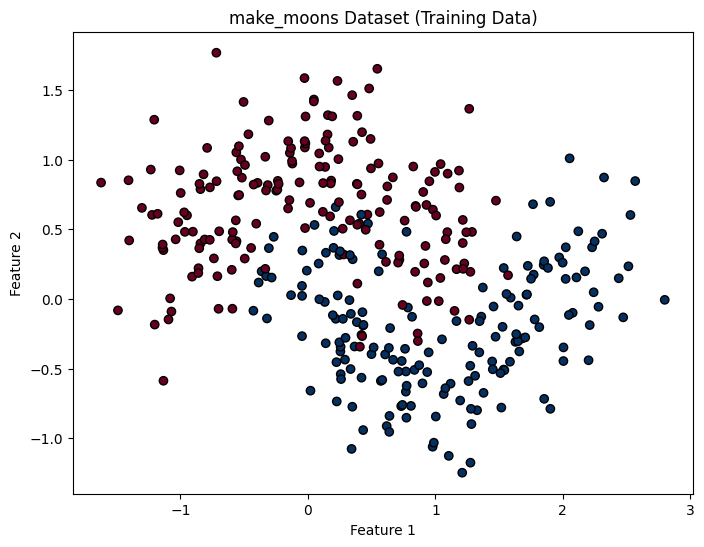

In [4]:
# Plot the training data to see its structure
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.RdBu, edgecolors='k')
plt.title("make_moons Dataset (Training Data)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### A Single Decision Tree (Baseline)

First, let's train a single Decision Tree as our baseline model. We will allow the tree to grow without restrictions on its depth to demonstrate how it can easily overfit the noisy training data.

In [5]:
# Train a single Decision Tree classifier
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X_train, y_train)
y_pred_tree = tree_clf.predict(X_test)
tree_accuracy = accuracy_score(y_test, y_pred_tree)
print(f"Single Decision Tree Accuracy: {tree_accuracy:.4f}")

Single Decision Tree Accuracy: 0.8533


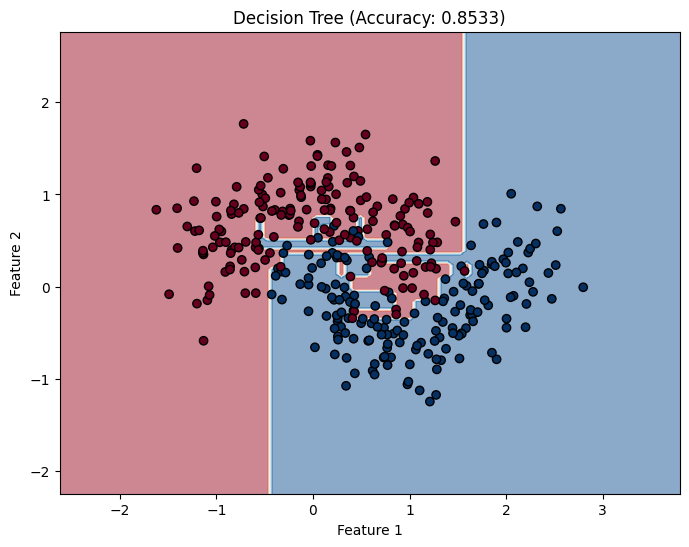

In [6]:
# Define a helper function to plot decision boundaries for our classifiers
def plot_decision_boundary(clf, X, y, ax, title):
    """Plots the decision boundary of a classifier."""
    # Use DecisionBoundaryDisplay for a clean and efficient plot
    disp = DecisionBoundaryDisplay.from_estimator(
        clf,
        X,
        response_method="predict",
        cmap=plt.cm.RdBu,
        alpha=0.5,
        ax=ax,
        xlabel="Feature 1",
        ylabel="Feature 2",
    )
    # Overlay the training data points
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdBu, edgecolors="k")
    ax.set_title(title)

# Plot its decision boundary
fig, ax = plt.subplots(figsize=(8, 6))
plot_decision_boundary(tree_clf, X_train, y_train, ax, f"Decision Tree (Accuracy: {tree_accuracy:.4f})")
plt.show()

Notice the complex, axis-parallel boundaries. The single decision tree creates an intricate boundary to perfectly classify every point in the training set, which is a classic sign of **overfitting**. This complexity means it likely won't generalize well to new, unseen data.

### Bagging (Bootstrap Aggregating)

Bagging involves training the same algorithm (e.g., a decision tree) on multiple random subsets of the training data. These subsets are created through **bootstrapping**, which means sampling with replacement. The final prediction is an aggregation (e.g., majority vote) of the predictions from each model. This process helps to reduce variance.

In [7]:
# Train a Bagging classifier with 500 Decision Trees
bag_clf = BaggingClassifier(
    DecisionTreeClassifier(random_state=42), # Base estimator
    n_estimators=500,                       # Number of trees in the ensemble
    max_samples=1.0,                        # Use all samples for each bootstrap
    bootstrap=True,                         # Enable bootstrapping
    n_jobs=-1,                              # Use all available CPU cores for training
    random_state=42
)
bag_clf.fit(X_train, y_train)
y_pred_bag = bag_clf.predict(X_test)
bag_accuracy = accuracy_score(y_test, y_pred_bag)
print(f"Bagging Classifier Accuracy: {bag_accuracy:.4f}")

Bagging Classifier Accuracy: 0.8933


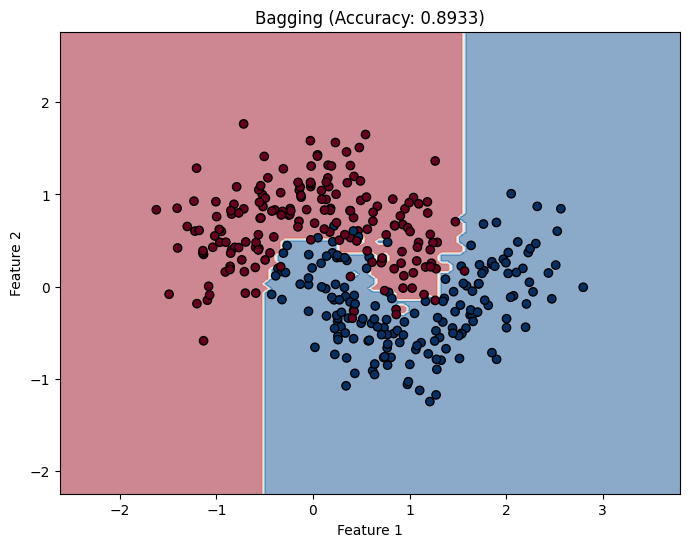

In [8]:
# Plot the decision boundary
fig, ax = plt.subplots(figsize=(8, 6))
plot_decision_boundary(bag_clf, X_train, y_train, ax, f"Bagging (Accuracy: {bag_accuracy:.4f})")
plt.show()

The decision boundary of the Bagging classifier is significantly smoother than the single tree's. By averaging the predictions of many trees, it reduces variance and creates a more robust model, often resulting in better accuracy on the test set.

### Random Forest

A Random Forest is an enhancement of Bagging. In addition to bootstrapping samples, it also introduces feature randomness: at each node split, it considers only a **random subset of features**. This helps to **decorrelate** the trees in the forest, which further reduces the model's variance and generally improves performance.

Random Forest Accuracy: 0.9000


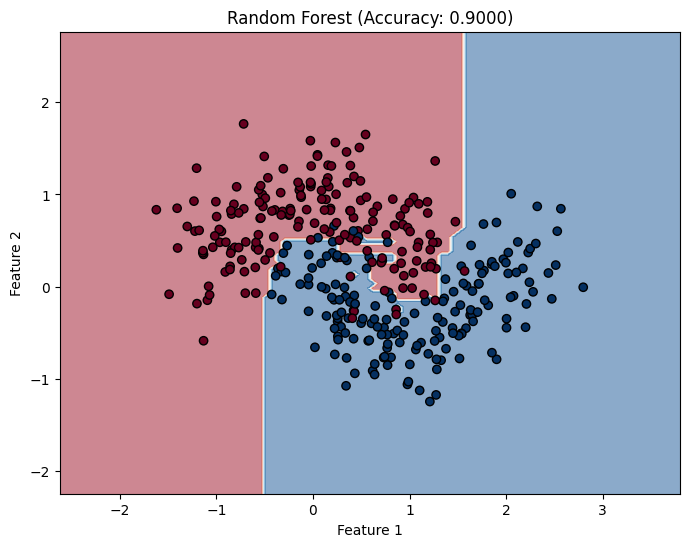

In [9]:
# Train a Random Forest classifier
rnd_clf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=42)
rnd_clf.fit(X_train, y_train)
y_pred_rf = rnd_clf.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {rf_accuracy:.4f}")

# Plot the decision boundary
fig, ax = plt.subplots(figsize=(8, 6))
plot_decision_boundary(rnd_clf, X_train, y_train, ax, f"Random Forest (Accuracy: {rf_accuracy:.4f})")
plt.show()

### Boosting

In contrast to Bagging, Boosting methods build models **sequentially**. Each new model is trained to correct the errors made by its predecessors, gradually building a strong combined model from a series of "weak" learners.

#### AdaBoost (Adaptive Boosting)

AdaBoost focuses on training samples that are hard to classify. It sequentially trains weak learners (e.g., decision stumps) and iteratively increases the weights of instances that were misclassified by previous learners. The final prediction is a weighted vote from all learners, with more accurate learners receiving a higher weight.

AdaBoost Classifier Accuracy: 0.8800


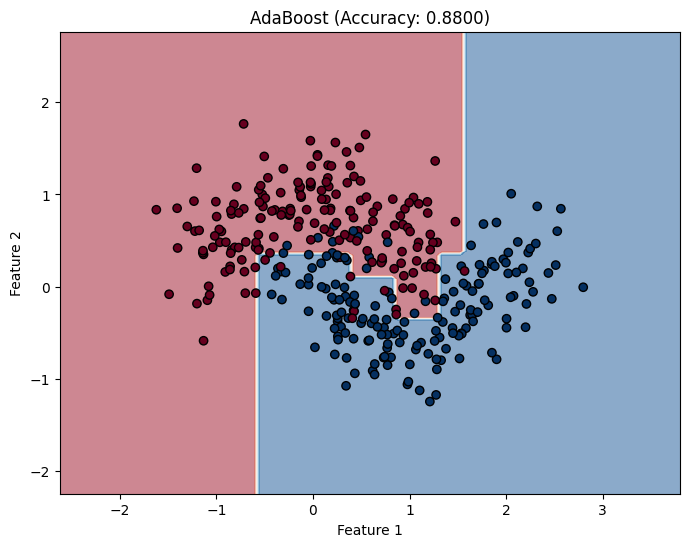

In [10]:
# Train an AdaBoost classifier
# The default base estimator is a Decision Tree with max_depth=1 (a decision stump)
ada_clf = AdaBoostClassifier(
    DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=200,
    learning_rate=0.5,
    random_state=42
)
ada_clf.fit(X_train, y_train)
y_pred_ada = ada_clf.predict(X_test)
ada_accuracy = accuracy_score(y_test, y_pred_ada)
print(f"AdaBoost Classifier Accuracy: {ada_accuracy:.4f}")

# Plot the decision boundary
fig, ax = plt.subplots(figsize=(8, 6))
plot_decision_boundary(ada_clf, X_train, y_train, ax, f"AdaBoost (Accuracy: {ada_accuracy:.4f})")
plt.show()

#### Gradient Boosting (GBDT)

Gradient Boosting also builds trees sequentially. However, instead of adjusting instance weights, each new tree is trained to predict the **residual errors** made by the sequence of previous trees. This is a very powerful and general technique.

Gradient Boosting Classifier Accuracy: 0.8867


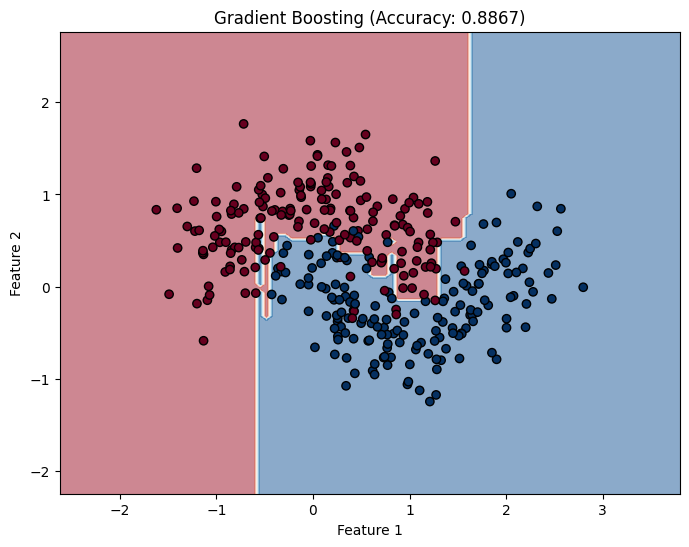

In [11]:
# Train a Gradient Boosting classifier
gbrt_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gbrt_clf.fit(X_train, y_train)
y_pred_gbrt = gbrt_clf.predict(X_test)
gbrt_accuracy = accuracy_score(y_test, y_pred_gbrt)
print(f"Gradient Boosting Classifier Accuracy: {gbrt_accuracy:.4f}")

# Plot the decision boundary
fig, ax = plt.subplots(figsize=(8, 6))
plot_decision_boundary(gbrt_clf, X_train, y_train, ax, f"Gradient Boosting (Accuracy: {gbrt_accuracy:.4f})")
plt.show()

#### XGBoost (Extreme Gradient Boosting)

XGBoost is a highly optimized and efficient implementation of the Gradient Boosting algorithm. It includes several improvements, such as built-in regularization to prevent overfitting and parallel processing capabilities, making it a go-to choice for many data science competitions.

XGBoost Classifier Accuracy: 0.8867


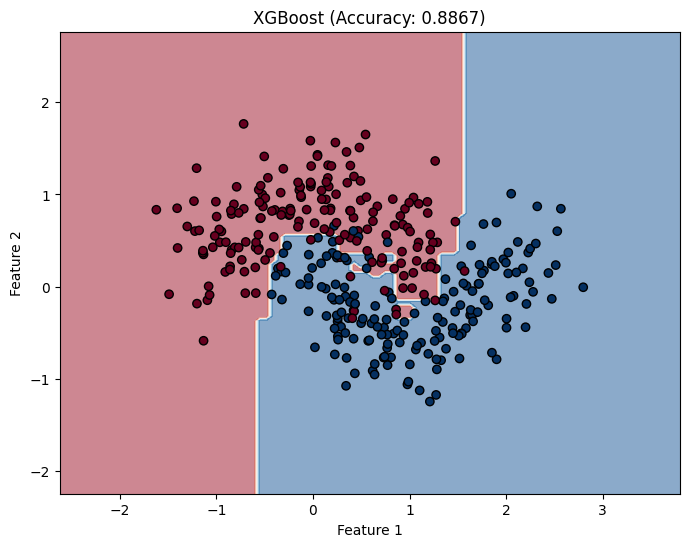

In [12]:
# Train an XGBoost classifier
# `use_label_encoder=False` and `eval_metric` are specified to avoid deprecation warnings
xgb_clf = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, eval_metric='logloss', random_state=42)
xgb_clf.fit(X_train, y_train)
y_pred_xgb = xgb_clf.predict(X_test)
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
print(f"XGBoost Classifier Accuracy: {xgb_accuracy:.4f}")

# Plot the decision boundary
fig, ax = plt.subplots(figsize=(8, 6))
plot_decision_boundary(xgb_clf, X_train, y_train, ax, f"XGBoost (Accuracy: {xgb_accuracy:.4f})")
plt.show()

In [13]:
# Summary of Results

# Create a pandas DataFrame to display the results clearly
results_df = pd.DataFrame({
    "Model": ["Single Decision Tree", "Bagging", "Random Forest", "AdaBoost", "Gradient Boosting", "XGBoost"],
    "Accuracy": [tree_accuracy, bag_accuracy, rf_accuracy, ada_accuracy, gbrt_accuracy, xgb_accuracy]
})

# Sort the results by accuracy to see which model performed best
print(results_df.sort_values(by="Accuracy", ascending=False))

                  Model  Accuracy
2         Random Forest  0.900000
1               Bagging  0.893333
5               XGBoost  0.886667
4     Gradient Boosting  0.886667
3              AdaBoost  0.880000
0  Single Decision Tree  0.853333


As we can see, all ensemble methods significantly outperformed the single, overfitted decision tree. This demonstrates the power of combining multiple models to create a more robust and accurate final predictor. Boosting methods often show slightly better performance than bagging methods, but this can depend heavily on the dataset and hyperparameter tuning. Both are powerful techniques to have in your machine learning toolkit.

## Support Vector Machines

To start, we first train a linear SVM and try to understand it.

In [14]:
data = load_iris()
print('Iris classes to predict: ', data.target_names)
# Extracting data attributes
X = data.data
print(X.shape)
### Extracting target/ class labels
y = data.target
print("y:", y.shape)

# we first select two features and two classes from iris for better visualization
X = X[:, [2, 3]]
print(X.shape)

# select for
class_0_index = np.where(y == 1)
class_1_index = np.where(y == 2)
X = np.concatenate((X[class_0_index], X[class_1_index]))
y = np.concatenate((y[class_0_index], y[class_1_index]))
print(X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, test_size = 0.25, stratify=y)

Iris classes to predict:  ['setosa' 'versicolor' 'virginica']
(150, 4)
y: (150,)
(150, 2)
(100, 2)


In [15]:
from sklearn.svm import SVC

mmc_clf = SVC(kernel="linear", random_state=42)
mmc_clf.fit(X_train, y_train)
mmc_clf.score(X_test, y_test)

0.88

Let's visualize the decision boundary of SVM for deeper understanding.

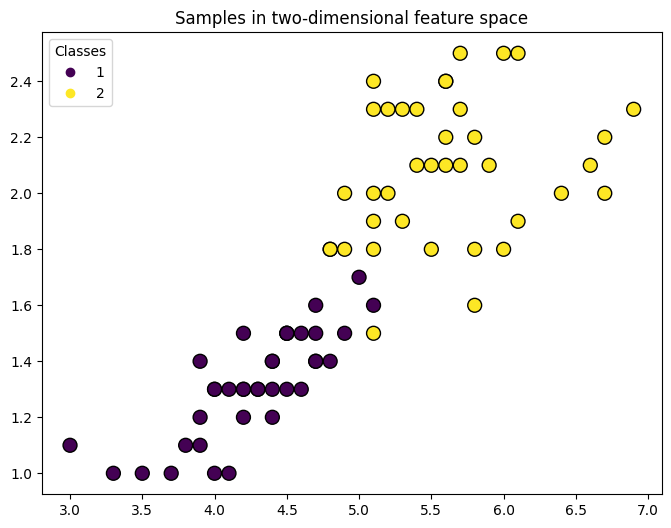

In [16]:
# Plotting settings
fig, ax = plt.subplots(figsize=(8, 6))

# Plot samples by color and add legend
scatter = ax.scatter(X_train[:, 0], X_train[:, 1], s=100, c=y_train, label=y_train, edgecolors="k")
ax.legend(*scatter.legend_elements(), loc="upper left", title="Classes")
ax.set_title("Samples in two-dimensional feature space")
_ = plt.show()

#### Visualize Decision Boundary

We define a function that fits a SVC classifier, allowing the kernel parameter as an input, and then plots the decision boundaries learned by the model using `DecisionBoundaryDisplay`.

In [17]:
from sklearn import svm
from sklearn.inspection import DecisionBoundaryDisplay


def plot_training_data_with_decision_boundary(
    kernel, ax=None, long_title=True, support_vectors=True
):
    # Train the SVC
    clf = svm.SVC(kernel=kernel, gamma=2).fit(X, y)

    # Settings for plotting
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3))
    # x_min, x_max, y_min, y_max = -3, 3, -3, 3
    # ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max))

    # Plot decision boundary and margins
    common_params = {"estimator": clf, "X": X, "ax": ax}
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="predict",
        plot_method="pcolormesh",
        alpha=0.3,
    )
    DecisionBoundaryDisplay.from_estimator(
        **common_params,
        response_method="decision_function",
        plot_method="contour",
        levels=[-1, 0, 1],
        colors=["k", "k", "k"],
        linestyles=["--", "-", "--"],
    )

    if support_vectors:
        # Plot bigger circles around samples that serve as support vectors
        ax.scatter(
            clf.support_vectors_[:, 0],
            clf.support_vectors_[:, 1],
            s=150,
            facecolors="none",
            edgecolors="k",
        )

    # Plot samples by color and add legend
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, s=30, edgecolors="k")
    ax.legend(*scatter.legend_elements(), loc="upper right", title="Classes")
    if long_title:
        ax.set_title(f" Decision boundaries of {kernel} kernel in SVC")
    else:
        ax.set_title(kernel)

    if ax is None:
        plt.show()

#### Linear Kernel

Linear kernel is the dot product of the input samples:
$$
K(x_1, x_2) = X_1^{T}X_2
$$

It is then applied to any combination of two data points (samples) in the dataset. The dot product of the two points determines the cosine_similarity between both points. The higher the value, the more similar the points are.

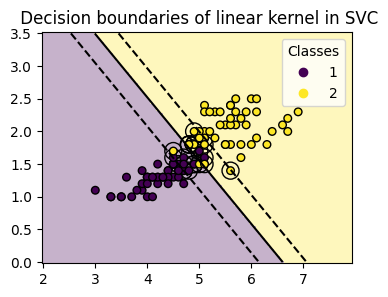

In [18]:
plot_training_data_with_decision_boundary("linear")

#### Polynomial kernel

The polynomial kernel changes the notion of similarity. The kernel function is defined as:
$$
K(x_1, x_2) = (\gamma \cdot x_1^{T}x_2 + r)^d
$$
where d is the degree (degree) of the polynomial, 
 $\gamma$ controls the influence of each individual training sample on the decision boundary and 
 r is the bias term (coef0) that shifts the data up or down.


In [19]:
mmc_clf = SVC(kernel="poly", random_state=42)
mmc_clf.fit(X_train, y_train)
mmc_clf.score(X_test, y_test)

0.84

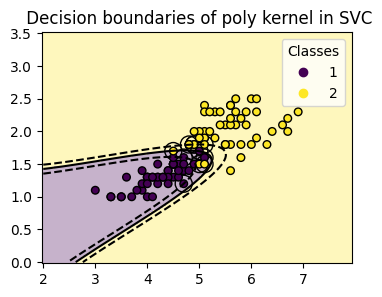

In [20]:
plot_training_data_with_decision_boundary("poly")

#### RBF kernel

The radial basis function (RBF) kernel, also known as the Gaussian kernel, is the default kernel for Support Vector Machines in scikit-learn. It measures similarity between two data points in infinite dimensions and then approaches classification by majority vote. The kernel function is defined as:
$$
K(x_1, x_2) = \mathrm{exp}(-\gamma \cdot ||x_1 - x_2||^2)
$$
where $\gamma$ controls the influence of each individual training sample on the decision boundary.

In [21]:
mmc_clf = SVC(kernel="rbf", random_state=42)
mmc_clf.fit(X_train, y_train)
mmc_clf.score(X_test, y_test)

0.92

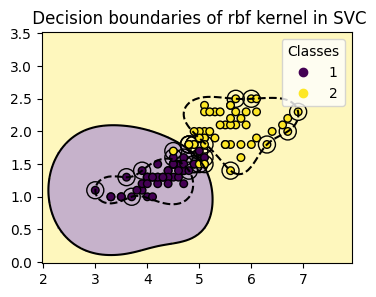

In [22]:
plot_training_data_with_decision_boundary("rbf")

#### Sigmoid kernel

The sigmoid kernel function is defined as:
$$
K(x_1, x_2) = \mathrm{tanh}(\gamma \cdot x_1^Tx_2 + r)
$$
where the kernel coefficient $\gamma$ controls the influence of each individual training sample on the decision boundary and 
r is the bias term (coef0) that shifts the data up or down.

In [23]:
mmc_clf = SVC(kernel="sigmoid", random_state=42)
mmc_clf.fit(X_train, y_train)
mmc_clf.score(X_test, y_test)

0.48

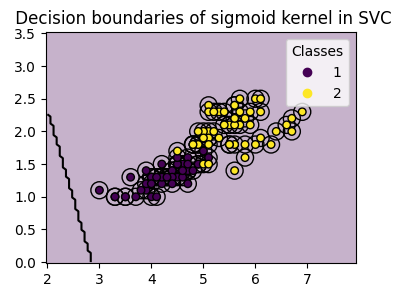

In [24]:
plot_training_data_with_decision_boundary("sigmoid")

#### Conclusion
In this example, we have visualized the decision boundaries trained with the provided dataset. The plots serve as an intuitive demonstration of how different kernels utilize the training data to determine the classification boundaries.

The hyperplanes and margins, although computed indirectly, can be imagined as planes in the transformed feature space. However, in the plots, they are represented relative to the original feature space, resulting in curved decision boundaries for the polynomial, RBF, and sigmoid kernels.

Please note that the plots do not evaluate the individual kernel’s accuracy or quality. They are intended to provide a visual understanding of how the different kernels use the training data.

#### Analysis on XOR dataset

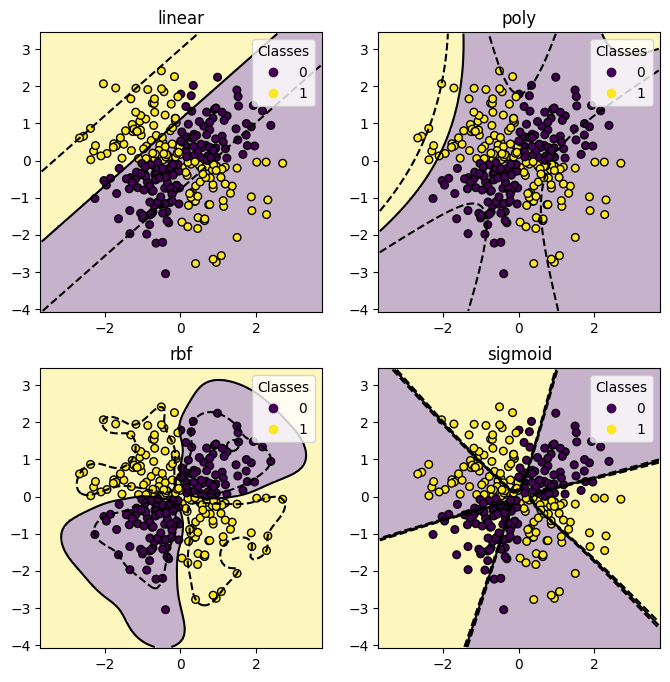

In [25]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 500), np.linspace(-3, 3, 500))
np.random.seed(0)
X = np.random.randn(300, 2)
y = np.logical_xor(X[:, 0] > 0, X[:, 1] > 0)

_, ax = plt.subplots(2, 2, figsize=(8, 8))
args = dict(long_title=False, support_vectors=False)
plot_training_data_with_decision_boundary("linear", ax[0, 0], **args)
plot_training_data_with_decision_boundary("poly", ax[0, 1], **args)
plot_training_data_with_decision_boundary("rbf", ax[1, 0], **args)
plot_training_data_with_decision_boundary("sigmoid", ax[1, 1], **args)
plt.show()